In [ ]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

100%|██████████| 170M/170M [00:15<00:00, 10.9MB/s]


In [ ]:
import torch.nn as nn

class AutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 64)
        )
        self.decoder = nn.Sequential(
            nn.Linear(64, 128 * 4 * 4),
            nn.LeakyReLU(),
            nn.Unflatten(1, (128, 4, 4)),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

In [ ]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
model = AutoEncoder().to(device)
risk = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history = []
for epoch in range(10):
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x = x.to(device)
        optimizer.zero_grad()
        x_f = model(x)
        loss = risk(x_f, x)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    history.append(total_loss / len(train_loader))
    print(f"Epoch: {epoch + 1} | Loss: {history[-1]}")


cuda
Epoch: 1 | Loss: 0.02050230649592893
Epoch: 2 | Loss: 0.010409419446268959
Epoch: 3 | Loss: 0.008654799412988374
Epoch: 4 | Loss: 0.00811755990483286
Epoch: 5 | Loss: 0.007944843276282367
Epoch: 6 | Loss: 0.007843011381614315
Epoch: 7 | Loss: 0.00776279529156473
Epoch: 8 | Loss: 0.007702533230709526
Epoch: 9 | Loss: 0.007642005366580489
Epoch: 10 | Loss: 0.007599270280898379


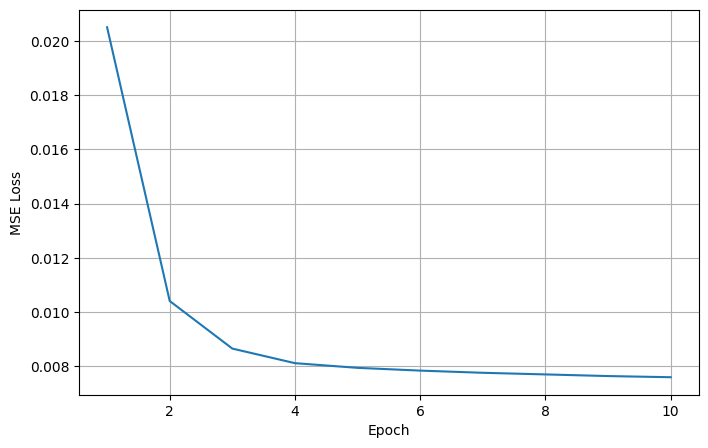

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid()
plt.show()

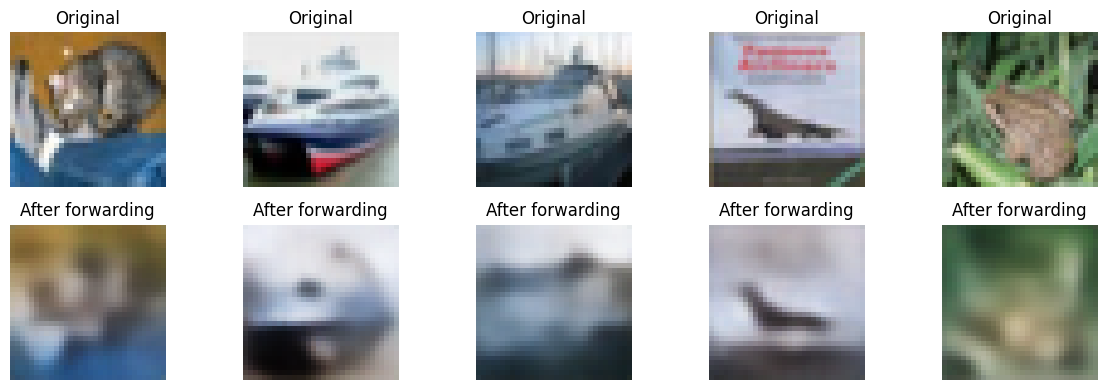

In [ ]:
model.eval()
imgs = next(iter(test_loader))[0][:5].to(device)
with torch.no_grad():
    imgs_f = model(imgs)
plt.figure(figsize=(12, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(imgs[i].cpu().permute(1, 2, 0))
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2, 5, i + 6)
    plt.imshow(imgs_f[i].cpu().permute(1, 2, 0))
    plt.title("After forwarding")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

vecs = []
X_all = []
y_all = []
with torch.no_grad():
    for x, y in train_loader:
        x = x.to(device)
        vec = model.encoder(x)
        vecs.append(vec.cpu().numpy())
        X_all.append(x.cpu().numpy())
        y_all.append(y.numpy())
vecs = np.concatenate(vecs)
X_all = np.concatenate(X_all)
y_all = np.concatenate(y_all)

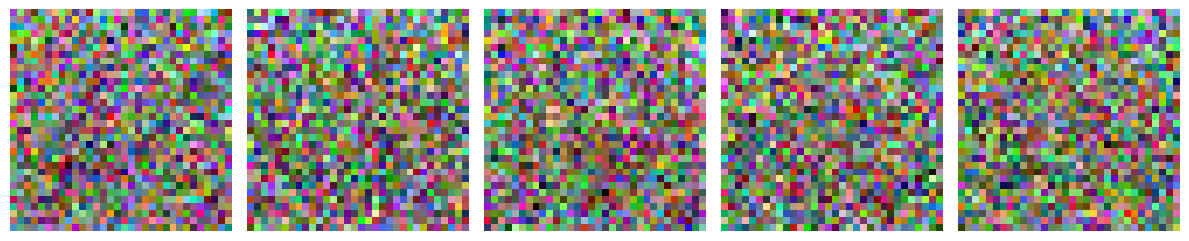

In [ ]:
flatten_x = X_all.reshape(len(X_all), -1)
mean = flatten_x.mean(axis=0)
std = flatten_x.std(axis=0)
gaussian_x = np.random.normal(loc=mean, scale=std, size=(5, flatten_x.shape[1]))
gaussian_x = np.clip(gaussian_x, 0, 1)
gaussian_x = gaussian_x.reshape(5, 3, 32, 32)
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(gaussian_x[i].transpose(1, 2, 0))
    plt.axis("off")
plt.tight_layout()
plt.show()

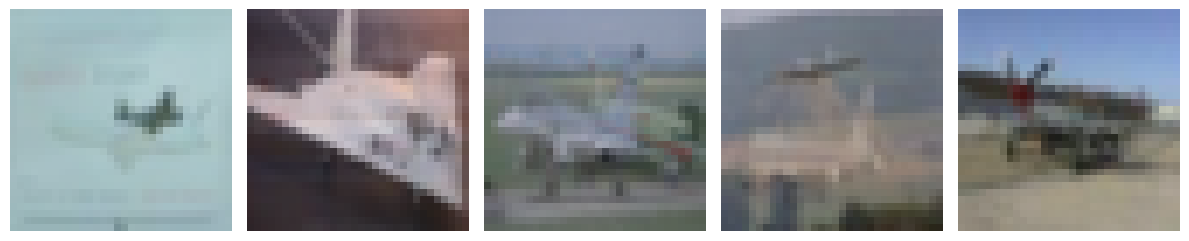

In [ ]:
from imblearn.over_sampling import SMOTE
i0 = np.where(y_all == 0)[0][:1000]
i1 = np.where(y_all == 1)[0][:5000]
idx = np.concat([i0, i1])
X_flatten_nw = flatten_x[idx]
y_nw = y_all[idx]
smote = SMOTE(k_neighbors=5)
X_smote, y_smote = smote.fit_resample(X_flatten_nw, y_nw)
new_gen = X_smote[len(X_flatten_nw):len(X_flatten_nw)+5]
plt.figure(figsize=(12, 3))
for i in range(5):
    img = new_gen[i].reshape(3, 32, 32)
    plt.subplot(1, 5, i + 1)
    plt.imshow(np.clip(img.transpose(1, 2, 0)))
    plt.axis("off")
plt.tight_layout()
plt.show()

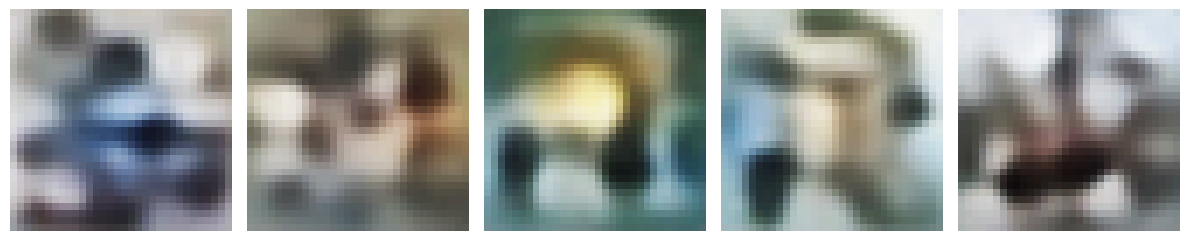

In [ ]:
vec_mean = vecs.mean(axis=0)
vec_std = vecs.std(axis=0)
gaussian_vec = np.random.normal(loc=vec_mean, scale=vec_std, size=(5, 64))
gaussian_vec = torch.tensor(gaussian_vec, dtype=torch.float32).to(device)
with torch.no_grad():
    gaussian_vec_img = model.decoder(gaussian_vec).cpu().numpy()
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(np.clip(gaussian_vec_img[i].transpose(1, 2, 0), 0, 1))
    plt.axis("off")
plt.tight_layout()
plt.show()

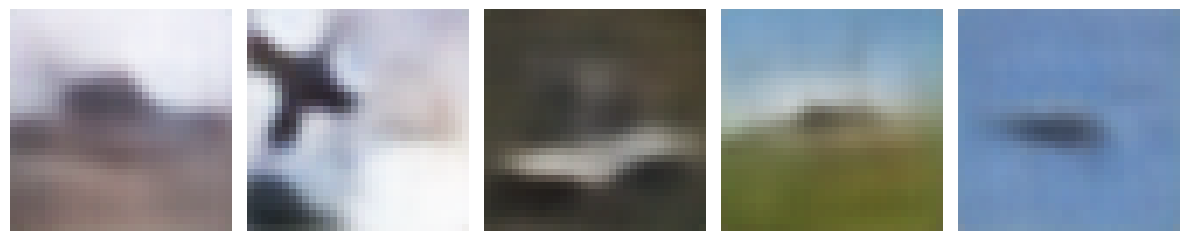

In [ ]:
X_vec_nw = vecs[idx]
smote = SMOTE(k_neighbors=5)
X_vec_nw_smote, y_nw_smote = smote.fit_resample(X_vec_nw, y_nw)
new_gen_vec = torch.tensor(X_vec_nw_smote[len(X_vec_nw):len(X_vec_nw)+5], dtype=torch.float32).to(device)
with torch.no_grad():
    smote_nw_img = model.decoder(new_gen_vec).cpu().numpy()
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(np.clip(smote_nw_img[i].transpose(1, 2, 0), 0, 1))
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_emb = nn.Embedding(10, 10)
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.Flatten()
        )

        self.fc_mu = nn.Linear(2048 + 10, 64)
        self.fc_logvar = nn.Linear(2048 + 10, 64)
        self.decoder_input = nn.Linear(64 + 10, 2048)

        self.decoder = nn.Sequential(
            nn.Unflatten(1, (128, 4, 4)),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def encode(self, x, y):
        h = self.encoder(x)
        y_emb = self.label_emb(y)
        h = torch.cat([h, y_emb], dim=1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, y):
        y_emb = self.label_emb(y)
        z = torch.cat([z, y_emb], dim=1)
        return self.decoder(self.decoder_input(z))

    def forward(self, x, y):
        mu, logvar = self.encode(x, y)
        z = self.reparameterize(mu, logvar)
        f = self.decode(z, y)
        return f, mu, logvar

In [ ]:
import torch.nn.functional as F
vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
history = []
for epoch in range(20):
    vae.train()
    total_loss = 0
    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        f, mu, logvar = vae(x, y)
        f_loss = F.mse_loss(f, x, reduction="sum")
        kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        loss = f_loss + kl_loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    history.append(total_loss / len(train_loader))
    print(f"Epoch: {epoch + 1} | Loss: {history[-1]}")


Epoch: 1 | Loss: 6221.840416793628
Epoch: 2 | Loss: 5022.706981141854
Epoch: 3 | Loss: 4896.399354120044
Epoch: 4 | Loss: 4840.255031575937
Epoch: 5 | Loss: 4804.22115862522
Epoch: 6 | Loss: 4781.284877455143
Epoch: 7 | Loss: 4759.011657714844
Epoch: 8 | Loss: 4742.734719669118
Epoch: 9 | Loss: 4730.441787290451
Epoch: 10 | Loss: 4719.648890502617
Epoch: 11 | Loss: 4713.296556711806
Epoch: 12 | Loss: 4702.486679818624
Epoch: 13 | Loss: 4698.781743198405
Epoch: 14 | Loss: 4691.447684753886
Epoch: 15 | Loss: 4685.217846180167
Epoch: 16 | Loss: 4683.328811840633
Epoch: 17 | Loss: 4678.050106585179
Epoch: 18 | Loss: 4672.2260206764
Epoch: 19 | Loss: 4667.526565590782
Epoch: 20 | Loss: 4663.712645235574


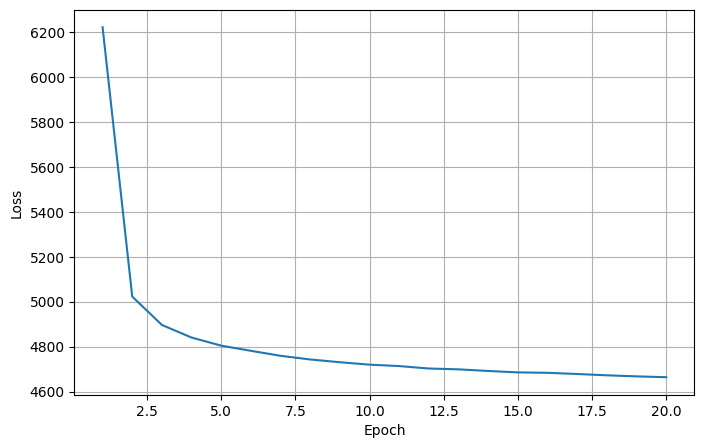

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(1, 21), history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.show()

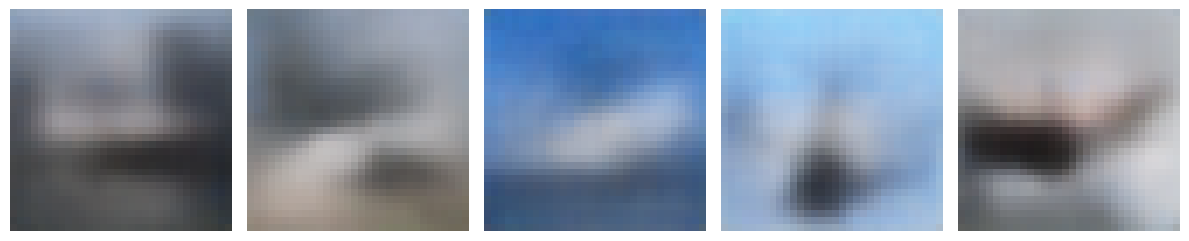

In [ ]:
vae.eval()
z = torch.randn(5, 64, device=device)
labels = torch.zeros(5, dtype=torch.long, device=device)
with torch.no_grad():
    generated = vae.decode(z, labels)
generated = generated.cpu().numpy()
plt.figure(figsize=(12, 3))
for i in range(5):
    image = generated[i].transpose(1, 2, 0)
    plt.subplot(1, 5, i + 1)
    plt.imshow(np.clip(image, 0, 1))
    plt.axis("off")
plt.tight_layout()
plt.show()

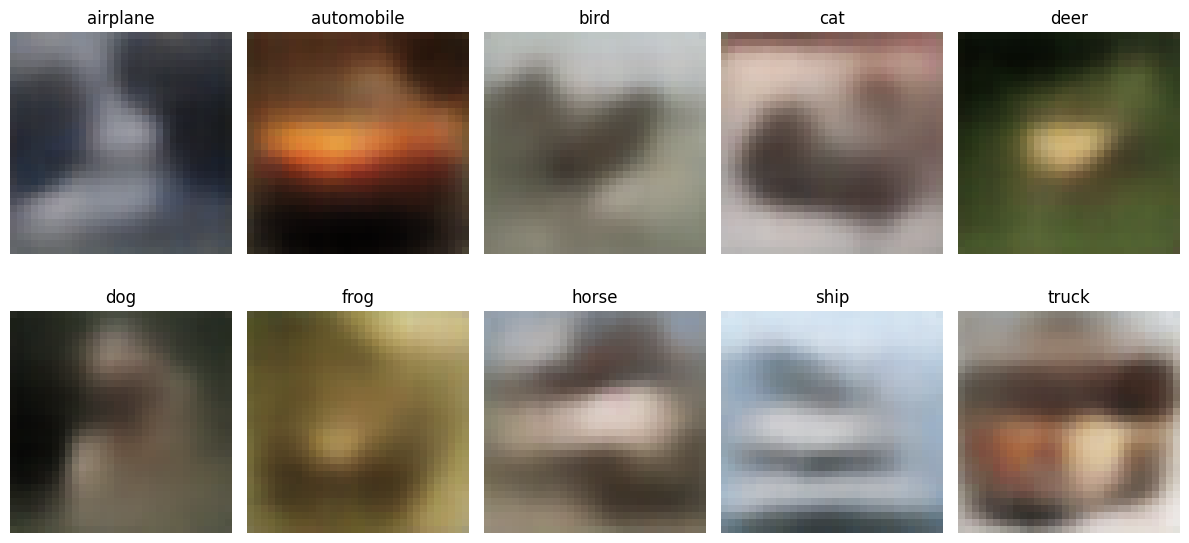

In [ ]:
z = torch.randn(10, 64, device=device)
labels = torch.arange(10, device=device)
with torch.no_grad():
    mixed_images = vae.decode(z, labels)
mixed_images = mixed_images.cpu().numpy()
plt.figure(figsize=(12, 6))
for i in range(10):
    image = mixed_images[i].transpose(1, 2, 0)
    plt.subplot(2, 5, i + 1)
    plt.imshow(np.clip(image, 0, 1))
    plt.title(train_dataset.classes[i])
    plt.axis("off")
plt.tight_layout()
plt.show()